# Directional coupler benchmark

Benchmarks Luminescent against Tidy3D and Lumerical FDTD using the directional coupler from Liu & Poon, [arXiv:2506.16665](https://arxiv.org/html/2506.16665v2), Sec. 3.1. The device is GDSFactory's generic `coupler`: two 500 nm × 220 nm Si arms, a 236 nm gap, and a 20 µm coupling length, with SiO2 cladding above and below. Si uses a lossless Lorentzian fit to the paper's Palik model (n = 3.4729 at 1550 nm); SiO2 is constant n = 1.4425. The domain is the device plus 1 µm margins: 42 × 6.5 × 2.22 µm³ (the paper uses 42 × 7 × 4 µm³). TE0 enters o1 (lower left) at 1550 nm with a λ/12 source bandwidth (the paper uses 20 nm). The energy shutoff is 1e-4 (1e-3 for nres ≤ 10; the paper uses 1e-5). We report the cross-port (o3) transmission, the excess loss, the solve time, and the peak memory against resolution.

Paper values (Tidy3D 2.7.7 on cloud A100 GPUs, Lumerical 2025 R1 on a 24-core CPU):

| nres | Tidy3D cross T | Lumerical cross T | Tidy3D time | Lumerical time | Lumerical memory |
|---|---|---|---|---|---|
| 6 | 69.7 % | 49.3 % | 17 s | 148 s | 0.35 GB |
| 10 | – | – | 35 s | 336 s | 0.92 GB |
| 15 | 44.8 % | 41.1 % | 66 s | 1293 s | 2.42 GB |

## Setup

In [1]:
import os, time, json, threading, subprocess
import numpy as np
import psutil
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

gf.gpdk.PDK.activate()

nres_list = [6, 10, 15]
h_wg = 0.22
wavelength = 1.55
# bandwidth = wavelength / 4
bandwidth = wavelength / 12
wavelengths = np.linspace(1.54, 1.56, 21).tolist()

# domain margins [um]
margin = 1
zmargin = 1
zmin, zmax = -zmargin, h_wg + zmargin

lumi backend: ~/Luminescent/bin/lumi


In [2]:
def setup(path, nres):
    # Si: lossless single-Lorentzian fit to the paper's Palik model (frequency in units of c / wavelength); SiO2: constant
    materials = {
        "Si": lumi.material(n=3.4729, epsilon=8.36218, dispersion=[lumi.lorentzian(3.0, 0, 3.2882)]),
        "SiO2": lumi.material(1.4425),
    }
    WG = 1, 0
    layer_stack = LayerStack(
        layers={
            "core": LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_wg,
                zmin=0,
                material="Si",
                mesh_order=0,
            ),
        }
    )

    # GDSFactory generic coupler: gap 0.236, length 20, dx 10, dy 4
    dc = gf.components.coupler(gap=0.236, length=20)
    xmin, ymin = dc.bbox_np()[0]
    xmax, ymax = dc.bbox_np()[1]
    bbox = [[xmin - margin, ymin - margin, zmin], [xmax + margin, ymax + margin, zmax]]

    # 10 um port extensions, cropped to the domain
    ext = gf.components.extend_ports(dc, length=10)
    dbu = ext.kcl.dbu
    arms = gf.kdb.Region(ext.begin_shapes_rec(ext.kcl.layer(*WG)))
    window = gf.kdb.Region(gf.kdb.Box(*(round(v / dbu) for v in (bbox[0][0], bbox[0][1], bbox[1][0], bbox[1][1]))))
    c = gf.Component()
    c.add_polygon(arms & window, layer=WG)
    for p in dc.ports:
        c.add_port(p.name, center=p.center, width=p.width, orientation=p.orientation, layer=WG)
    c.plot()

    frames = [
        lumi.plane_frame(
            "wg",
            start=[-1.2, zmin],
            stop=[1.2, zmax],
            wls_mode_solver=[wavelengths[0], wavelength, wavelengths[-1]],
        )
    ]
    sources = [
        lumi.gf_source("o1", c, layer_stack, margin, frame="wg", wl=wavelength, bandwidth=bandwidth)
    ]
    monitors = [lumi.gf_monitor(p, c, layer_stack, frame="wg") for p in ["o1", "o2", "o3", "o4"]]

    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background="SiO2",
        boundaries=["PML", "PML", "PML"],
        PML_decay=[0.001, 0.001, 0.1],
        bbox=bbox,
        frames=frames,
        sources=sources,
        monitors=monitors,
        nres=nres,
        tmax=1000,  # periods
        shutoff=1e-4,
        views=[lumi.view("Hz", z=h_wg / 2)],
        shot_every=10,
    )
    return c

## Simulate

In [3]:
def gpu_used():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
    return sum(float(v) for v in out.split()) / 1024  # GB


def solve_with_stats(path):
    """solve, tracking wall time, peak GPU memory (above baseline) and peak solver host RSS"""
    peak = {"gpu": 0.0, "host": 0.0}
    base = gpu_used()
    me = psutil.Process()
    done = threading.Event()

    def poll():
        while not done.is_set():
            peak["gpu"] = max(peak["gpu"], gpu_used() - base)
            rss = 0
            for p in me.children(recursive=True):
                try:
                    rss += p.memory_info().rss
                except psutil.Error:
                    pass
            peak["host"] = max(peak["host"], rss / 1024**3)
            time.sleep(0.5)

    t = threading.Thread(target=poll)
    t.start()
    t0 = time.time()
    try:
        lumi.solve(path)
    finally:
        done.set()
        t.join()
    stats = {"runtime": time.time() - t0, "gpu_GB": peak["gpu"], "host_GB": peak["host"]}
    json.dump(stats, open(os.path.join(path, "stats.json"), "w"))
    return stats

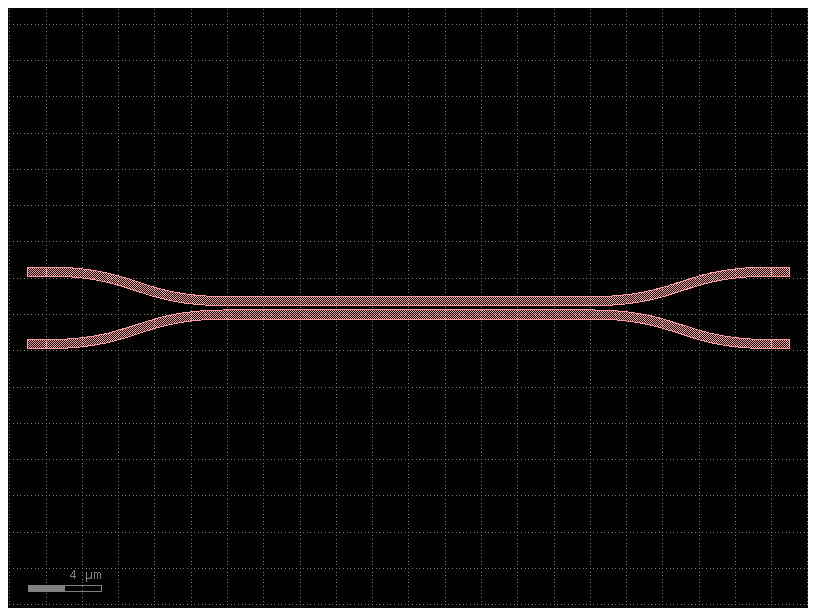

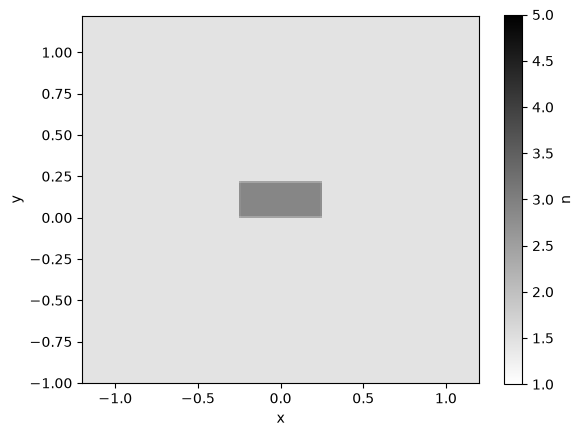

using simulation folder runs/dc_nres6


backend using simulation folder runs/dc_nres6


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 10.947417 seconds (509.27 M allocations: 20.249 GiB, 27.56% gc time, 128.57% compilation time)


... (17 outputs left out)

period 210, decay: 0.004, 0.014 seconds/period, 9903.24 Mcells/s
period 220, decay: 0.004, 0.013 seconds/period, 10792.92 Mcells/s


period 230, decay: 0.003, 0.012 seconds/period, 11076.01 Mcells/s
period 240, decay: 0.002, 0.013 seconds/period, 10668.04 Mcells/s
period 244.09 stop on energy decay
10389.65 Mcells/s


simulation completed.


{'runtime': 137.52924180030823, 'gpu_GB': 1.3603515625, 'host_GB': 2.5383262634277344}


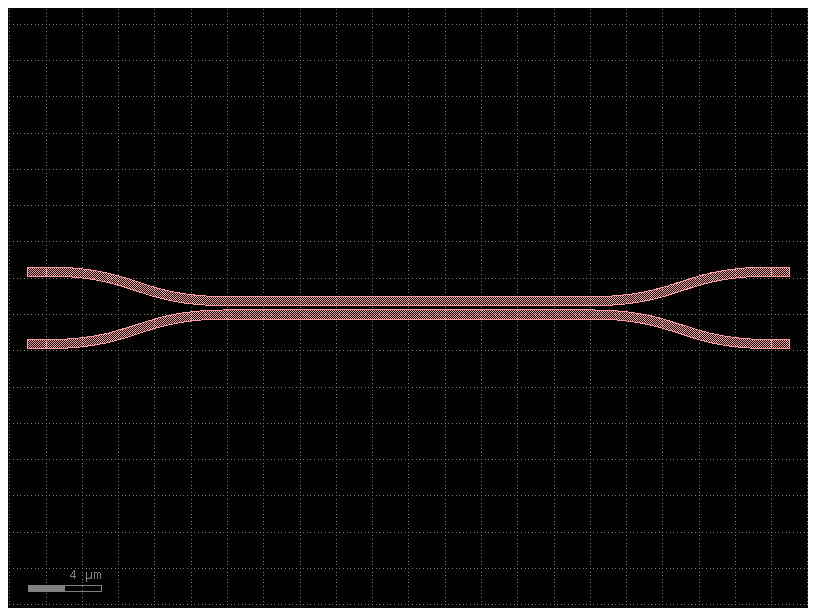

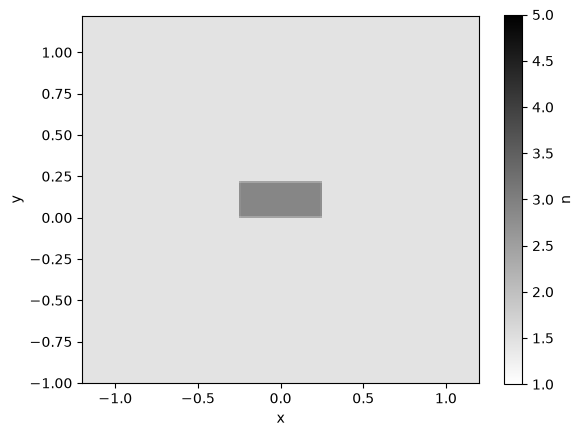

using simulation folder runs/dc_nres10


backend using simulation folder runs/dc_nres10


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 27.278463 seconds (1.40 G allocations: 53.044 GiB, 35.67% gc time, 54.05% compilation time)


... (20 outputs left out)

period 130, decay: 0.002, 0.098 seconds/period, 9179.19 Mcells/s


period 135.53 stop on energy decay
8930.73 Mcells/s


simulation completed.


{'runtime': 157.68253374099731, 'gpu_GB': 3.6103515625, 'host_GB': 3.8725433349609375}


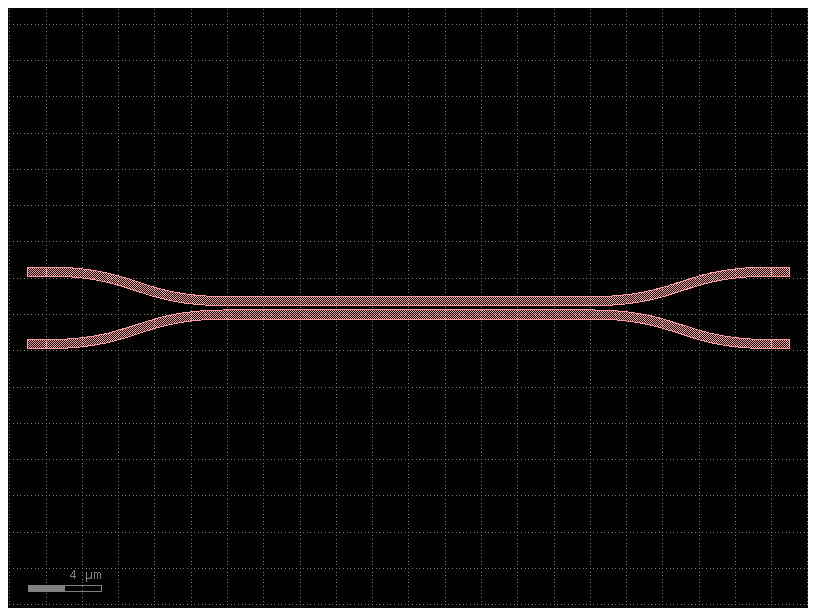

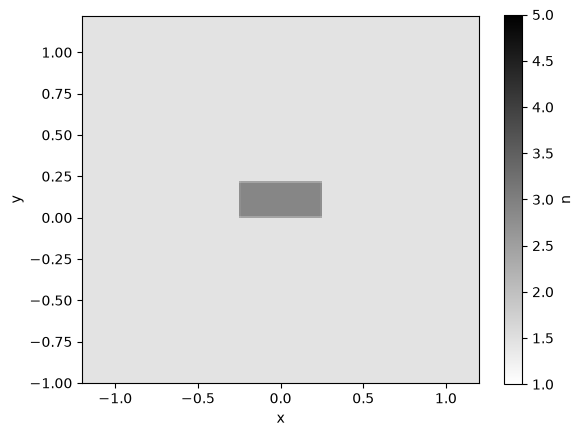

using simulation folder runs/dc_nres15


backend using simulation folder runs/dc_nres15


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 39.680508 seconds (3.35 G allocations: 124.395 GiB, 33.61% gc time, 62.37% compilation time)


... (30 outputs left out)

period 230, decay: 0.0, 0.53 seconds/period, 7659.09 Mcells/s


period 231.92 stop on energy decay
7614.26 Mcells/s


simulation completed.


{'runtime': 287.3348059654236, 'gpu_GB': 11.5478515625, 'host_GB': 5.112232208251953}


In [4]:
for nres in nres_list:
    path = os.path.join("runs", f"dc_nres{nres}")
    setup(path, nres)
    print(solve_with_stats(path))

## Results

loading solution from runs/dc_nres6
may take a minute if simulation folder is remotely mounted
loading solution from runs/dc_nres10
may take a minute if simulation folder is remotely mounted
loading solution from runs/dc_nres15
may take a minute if simulation folder is remotely mounted
nres  cross T  through T  excess loss  runtime  GPU mem  host mem
   6    43.6 %     51.4 %     0.223 dB    138 s   1.36 GB   2.54 GB
  10    41.3 %     57.8 %     0.040 dB    158 s   3.61 GB   3.87 GB
  15    43.3 %     55.8 %     0.038 dB    287 s  11.55 GB   5.11 GB


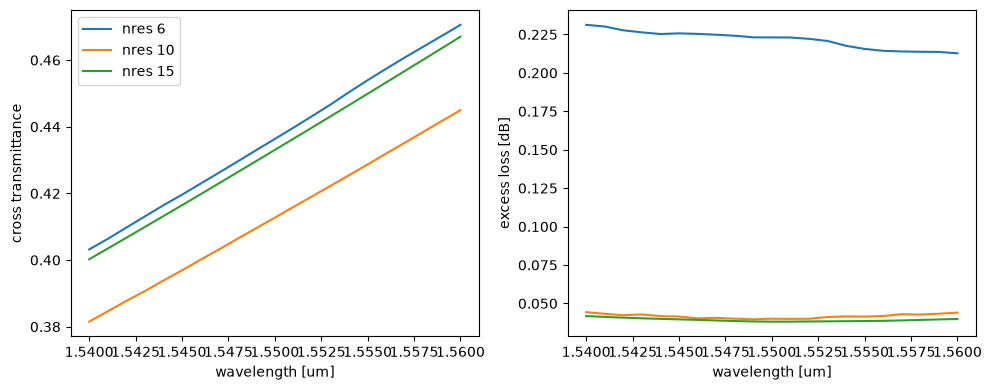

In [5]:
wls = np.array(wavelengths)
i = np.argmin(abs(wls - wavelength))
rows = []
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for nres in [6, 10, 15]:
    path = os.path.join("runs", f"dc_nres{nres}")
    if not os.path.exists(os.path.join(path, "solution.json")):
        continue
    m = lumi.load(path)["monitors"]
    a1 = m["o1"]["modes"][0]["-"]
    T3 = np.abs(m["o3"]["modes"][0]["+"] / a1) ** 2  # cross
    T4 = np.abs(m["o4"]["modes"][0]["+"] / a1) ** 2  # through
    loss = -10 * np.log10(T3 + T4)
    f = os.path.join(path, "stats.json")
    st = json.load(open(f)) if os.path.exists(f) else {}
    rows.append((nres, T3[i], T4[i], loss[i], st.get("runtime"), st.get("gpu_GB"), st.get("host_GB")))
    ax[0].plot(wls, T3, label=f"nres {nres}")
    ax[1].plot(wls, loss, label=f"nres {nres}")

fmt = lambda v, f: "–" if v is None else format(v, f)
print("nres  cross T  through T  excess loss  runtime  GPU mem  host mem")
for nres, t3, t4, l, rt, g, h in rows:
    print(f"{nres:4d}  {100*t3:6.1f} %  {100*t4:7.1f} %  {l:8.3f} dB  {fmt(rt, '5.0f'):>5} s  {fmt(g, '5.2f'):>5} GB  {fmt(h, '5.2f'):>5} GB")

ax[0].set(xlabel="wavelength [um]", ylabel="cross transmittance")
ax[1].set(xlabel="wavelength [um]", ylabel="excess loss [dB]")
ax[0].legend()
plt.tight_layout()
plt.show()

## Fig. 4a comparison

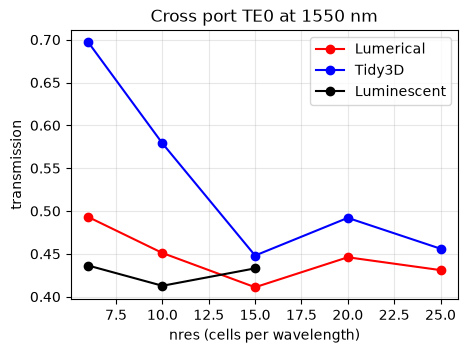

In [6]:
# paper Fig. 4a, digitized
nres_paper = [6, 10, 15, 20, 25]
T_tidy3d = [0.697, 0.579, 0.448, 0.492, 0.456]
T_lumerical = [0.493, 0.451, 0.411, 0.446, 0.431]

plt.figure(figsize=(5, 3.5))
plt.plot(nres_paper, T_lumerical, "o-", color="red", label="Lumerical")
plt.plot(nres_paper, T_tidy3d, "o-", color="blue", label="Tidy3D")
plt.plot([r[0] for r in rows], [r[1] for r in rows], "o-", color="black", label="Luminescent")
plt.xlabel("nres (cells per wavelength)")
plt.ylabel("transmission")
plt.title("Cross port TE0 at 1550 nm")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Movie

In [7]:
nres_list = [6]